# Notebook 7: Víctimas viales y cámaras de velocidad en Bogotá

Este notebook carga los datos procesados y construye las gráficas que sustentan los dos hallazgos del proyecto. Las mismas gráficas se muestran en el dashboard de Streamlit (`src/dashboard_streamlit.py`).

**Decisiones de análisis**

- **Período:** El análisis usa solo las víctimas de 2019 a 2025. Las excepciones son las gráficas 5 y 6, que necesitan los años anteriores (2015-2018) para mostrar cual era el promedio de accidentes antes y despues.
- **Radio de 300 m (Al final usamos tambien de 500 m para comparar):** Es aproximadamente el alcance de una cámara de velocidad. Un radio mayor cubriría casi toda la ciudad y ayudaría poco a decidir dónde hay cobertura. 
- **Distancia a las cámaras:** se mide contra las ubicaciones actuales de las cámaras (`camaras.csv` no trae fecha de instalación), por lo que "cerca de una cámara" significa cerca de un punto donde hoy hay una.



In [1]:
import pandas as pd
import numpy as np
import plotly.express as px

RUTA = "../data/processed/"
RADIO = 300
TAMANIO_CUADRO = 0.0027

victimas_camaras_anio = "AA_Acc"
victimas_camaras_dist = "distancia_m"
victimas_camaras_tipo = "Condicion"
victimas_camaras_franja = "franja"
victimas_camaras_lat = "Latitud"
victimas_camaras_lon = "Longitud"
victimas_camaras_cuadro = "cuadro"

cuadros_nombre = "cuadro"
cuadros_nvict = "victimas"
cuadros_dist = "distancia_min"

localidades_nombre = "localidad"
localidades_tasa = "tasa_victimas"
localidades_cam = "camaras"

## Carga de datos

Se cargan tres archivos de `data/processed`:

- `victimas_camaras.csv.gz`: una fila por víctima, con su ubicación, tipo, franja horaria y la distancia a la cámara más cercana.
- `cuadros.csv`: puntos de la ciudad (cuadros de unos 300 m) ordenados de mayor a menor número de víctimas.
- `localidades.csv`: víctimas por 100.000 habitantes y número de cámaras de cada localidad.

El archivo de víctimas no trae el cuadro al que pertenece cada una, así que se calcula redondeando latitud y longitud a una malla de 0,0027 grados (unos 300 m), igual que en `cuadros.csv`. Se guarda en `victimas_camaras_2019` la versión filtrada desde 2019, que es la que usan casi todas las gráficas.

El chequeo final confirma que el cuadro quedó bien construido: deben salir 260, 257 y 255 víctimas, igual que en los tres primeros puntos de `cuadros.csv`

In [2]:
victimas_camaras = pd.read_csv(RUTA + "victimas_camaras.csv.gz")
cuadros = pd.read_csv(RUTA + "cuadros.csv")
localidades = pd.read_csv(RUTA + "localidades.csv")

fila = np.round(victimas_camaras[victimas_camaras_lat] / TAMANIO_CUADRO).astype(int)
columna = np.round(victimas_camaras[victimas_camaras_lon] / TAMANIO_CUADRO).astype(int)
victimas_camaras[victimas_camaras_cuadro] = fila.astype(str) + "_" + columna.astype(str)

victimas_camaras_2019 = victimas_camaras[victimas_camaras[victimas_camaras_anio] >= 2019]

print(victimas_camaras_2019[victimas_camaras_cuadro].value_counts().head(3))
print(cuadros[[cuadros_nombre, cuadros_nvict]].head(3))

cuadro
1714_-27448    260
1703_-27474    257
1703_-27461    255
Name: count, dtype: int64
        cuadro  victimas
0  1714_-27448       260
1  1703_-27474       257
2  1703_-27461       255


In [3]:
print(cuadros.shape)
print(cuadros.dtypes)
print(cuadros.head(3))

(3925, 12)
cuadro                  str
victimas              int64
muertos               int64
latitud             float64
longitud            float64
distancia_min       float64
localidad               str
direccion               str
actor_principal         str
franja_principal        str
tiene_camara           bool
puesto                int64
dtype: object
        cuadro  victimas  muertos   latitud   longitud  distancia_min  \
0  1714_-27448       260        7  4.627833 -74.109302     412.076357   
1  1703_-27474       257        5  4.597461 -74.179590     294.675102   
2  1703_-27461       255       10  4.598402 -74.144987     420.920019   

       localidad                               direccion actor_principal  \
0  PUENTE ARANDA  AV AVENIDA DE LAS AMERICAS - KR 53  02    MOTOCICLISTA   
1           BOSA                      AU SUR - KR 76  02    MOTOCICLISTA   
2        KENNEDY          AV AVENIDA BOYACA - CL 44 S 02    MOTOCICLISTA   

  franja_principal  tiene_camara  puesto 

In [4]:
print(localidades.shape)
print(localidades.dtypes)
print(localidades.head(3))

(20, 8)
localidad                  str
victimas                 int64
muertos                  int64
poblacion_suma           int64
tasa_victimas          float64
tasa_muertos           float64
camaras                float64
victimas_por_camara    float64
dtype: object
        localidad  victimas  muertos  poblacion_suma  tasa_victimas  \
0    LOS MÁRTIRES      4756      120          581791     817.475691   
1  ANTONIO NARIÑO      3708       88          581749     637.388289   
2        SANTA FE      4750      140          752232     631.454126   

   tasa_muertos  camaras  victimas_por_camara  
0     20.625964      0.0                  NaN  
1     15.126799      1.0               3708.0  
2     18.611279      2.0               2375.0  


In [5]:
pct_cerca = (victimas_camaras_2019[victimas_camaras_dist] <= RADIO).mean() * 100
pct_lejos = 100 - pct_cerca
print(f"A {RADIO} m o menos: {pct_cerca:.1f}%  |  Más lejos: {pct_lejos:.1f}%")

g1 = pd.DataFrame([[f"≤ {RADIO} m", pct_cerca], [f"> {RADIO} m", pct_lejos]],
                  columns=["zona", "pct"])

fig1 = px.bar(g1, x="zona", y="pct", text_auto=".1f", color="zona",
              title="Víctimas según distancia a la cámara más cercana")
fig1.update_layout(yaxis_title="% de las víctimas", showlegend=False, title_x=0.5, xaxis_title="Distancia a la cámara más cercana")
fig1.show()

A 300 m o menos: 8.8%  |  Más lejos: 91.2%


In [6]:
g2 = cuadros.head(10)
g2["Cámara"] = np.where(g2[cuadros_dist] <= RADIO, "Con cámara", "Sin cámara")
g2[cuadros_nombre] = g2[cuadros_nombre].astype(str)

fig2 = px.bar(g2, x=cuadros_nvict, y=cuadros_nombre, color="Cámara", orientation="h",
              title="  10 puntos con más víctimas")
fig2.update_yaxes(autorange="reversed")
fig2.update_layout(title_x=0.5)
fig2.show()

In [7]:
top50 = cuadros.head(50)
puntos_sin = top50[top50[cuadros_dist] > RADIO]
vic_sin = victimas_camaras_2019[victimas_camaras_2019[victimas_camaras_cuadro].isin(puntos_sin[cuadros_nombre])]
print("Puntos críticos sin cámara:", len(puntos_sin), "de 50")
print("Víctimas en esos puntos:", len(vic_sin))

g3a = vic_sin[victimas_camaras_tipo].value_counts(normalize=True).mul(100).reset_index()
g3a.columns = ["tipo", "pct"]

fig3a = px.bar(g3a, x="pct", y="tipo", orientation="h",
               title="Tipo de víctima en puntos críticos sin cámara")
fig3a.update_layout(xaxis_title="% de las víctimas", title_x=0.5, yaxis_title="Tipo de víctima")
fig3a.update_yaxes(autorange="reversed")
fig3a.show()

orden = ["Madrugada (0-5)", "Mañana (6-11)", "Tarde (12-17)", "Noche (18-23)"]
g3b = vic_sin[victimas_camaras_franja].value_counts(normalize=True).reindex(orden).mul(100).reset_index()
g3b.columns = ["franja", "pct"]

fig3b = px.bar(g3b, x="franja", y="pct",
               title="Franja horaria en puntos críticos sin cámara")
fig3b.update_layout(yaxis_title="% de las víctimas", title_x=0.5, xaxis_title="Franja horaria")
fig3b.show()

Puntos críticos sin cámara: 34 de 50
Víctimas en esos puntos: 7114


In [8]:
g4 = localidades.sort_values(localidades_tasa, ascending=False)

fig4a = px.bar(g4, x=localidades_tasa, y=localidades_nombre, orientation="h",
               title="Víctimas por 100.000 habitantes")
fig4a.update_yaxes(autorange="reversed")
fig4a.update_layout(yaxis_title="Localidad", xaxis_title="Víctimas por 100.000 habitantes", title_x=0.5)
fig4a.show()

fig4b = px.bar(g4, x=localidades_cam, y=localidades_nombre, orientation="h",
               title="Número de cámaras por localidad")
fig4b.update_yaxes(autorange="reversed")
fig4b.show()

zona    Cerca de una cámara  Resto de la ciudad
AA_Acc                                         
2015                   1169               12654
2016                   1273               12755
2017                   1279               13119
2018                   1502               16101
2019                   1672               16180
2020                   1083               12006
2021                   1625               17213
2022                   2101               19445
2023                   2036               21496
2024                   2043               21111
2025                   1606               18561
Cambio entre 2015-2018 y 2022-2025 (%):
zona
Cerca de una cámara    49.1
Resto de la ciudad     47.6
dtype: float64


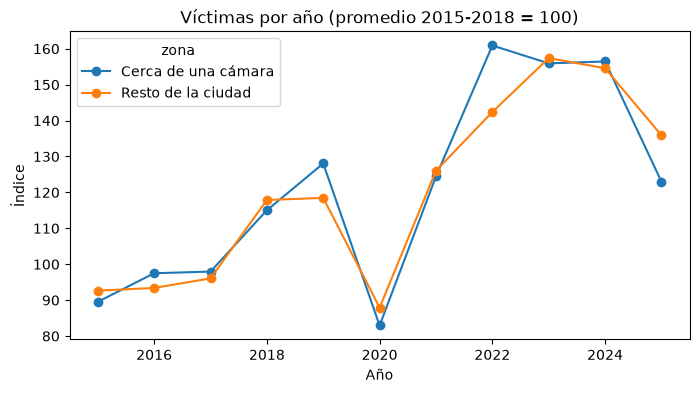

In [9]:
g5 = victimas_camaras.copy()
g5[victimas_camaras_anio] = g5[victimas_camaras_anio].astype(int)
g5["zona"] = np.where(g5[victimas_camaras_dist] <= RADIO, "Cerca de una cámara", "Resto de la ciudad")

# Víctimas por año en cada zona
por_anio = g5.groupby([victimas_camaras_anio, "zona"]).size().unstack(fill_value=0)
print(por_anio)

base = por_anio[por_anio.index <= 2018].mean()
despues = por_anio[por_anio.index >= 2022].mean()
cambio = (despues - base) / base * 100
print("Cambio entre 2015-2018 y 2022-2025 (%):")
print(cambio.round(1))

indice = por_anio / base * 100
grafica = indice.plot(marker="o", figsize=(8, 4), title="Víctimas por año (promedio 2015-2018 = 100)",
                      xlabel="Año", ylabel="Índice")

In [10]:
g6 = victimas_camaras.copy()
g6[victimas_camaras_anio] = g6[victimas_camaras_anio].astype(int)

por_anio_total = g6.groupby(victimas_camaras_anio).size().reset_index()
por_anio_total.columns = ["anio", "victimas"]
por_anio_total["Período"] = np.where(por_anio_total["anio"] < 2019, "Antes de 2019", "Desde 2019")

promedio_antes = por_anio_total[por_anio_total["anio"] < 2019]["victimas"].mean()
promedio_despues = por_anio_total[por_anio_total["anio"] >= 2019]["victimas"].mean()
print(f"Promedio anual antes de 2019: {promedio_antes:.0f}  |  Desde 2019: {promedio_despues:.0f}")

fig6 = px.bar(por_anio_total, x="anio", y="victimas", color="Período", text_auto=True,
              title="Víctimas por año en toda la ciudad")
fig6.update_layout(xaxis_title="Año", yaxis_title="Víctimas", title_x=0.5)
fig6.update_xaxes(dtick=1)
fig6.show()

Promedio anual antes de 2019: 14963  |  Desde 2019: 19740


## Gráfica 1: ¿Qué porcentaje de las víctimas estuvo cerca de una cámara?

Se compara la distancia de cada víctima a su cámara más cercana con el radio de 300 m. El promedio de esa comparación da el porcentaje de víctimas cerca de una cámara, y el resto quedó más lejos. Resultado: solo el **8,8 %** de las víctimas ocurrió a 300 m o menos de una cámara.

## Gráfica 2: Los 10 puntos con más víctimas

`cuadros.csv` ya viene ordenado de mayor a menor número de víctimas, así que se toman los 10 primeros. Cada punto se pinta de un color según tenga o no una cámara a 300 m o menos.

## Gráfica 3: Víctimas en los puntos críticos sin cámara

Los puntos críticos son los 50 primeros de `cuadros.csv`. De ellos se toman los que no tienen cámara a menos de 300 m (**34 de 50**) y se buscan las víctimas de esos cuadros (7.114). La primera gráfica muestra qué tipo de víctima es: la mitad (**50,2 %**) son motociclistas. La segunda muestra la franja horaria: mañana 29,1 %, noche 28,2 %, tarde 26,3 % y madrugada 16,4 %.

## Gráfica 4: Localidades

`localidades.csv` ya trae la tasa de víctimas por 100.000 habitantes. Se muestra junto al número de cámaras de cada localidad, en el mismo orden, para comparar fila por fila si las localidades con más víctimas tienen más o menos cámaras.

## Gráfica 5: Víctimas por año, cerca de cámaras vs resto de la ciudad (2015-2025)

Se cuentan las víctimas por año separando las que ocurrieron a 300 m o menos de una cámara de las del resto de la ciudad. Cada año se divide entre el promedio de 2015 a 2018 de su misma zona (antes de las cámaras), para comparar el cambio y no el tamaño de cada grupo. Entre 2015-2018 y 2022-2025 las víctimas subieron 49,1 % cerca de las cámaras y 47,6 % en el resto: casi igual.

## Gráfica 6: Víctimas antes y después de 2019

Muestra el total de víctimas de la ciudad por año, desde 2015, sin separar por cámaras. Las barras se colorean según sean anteriores a 2019 o desde 2019, año en que se añadieron las cámaras. El promedio anual pasa de unas 14.960 víctimas (2015-2018) a unas 19.740 (2019-2025), y en 2020 hay una caída marcada. Junto con la gráfica 5, es la que usa todos los años.

In [11]:
radios = [300, 500]
filas = []

for r in radios:
    pct = (victimas_camaras_2019[victimas_camaras_dist] <= r).mean() * 100
    sin_r = top50[top50[cuadros_dist] > r]
    vic_r = victimas_camaras_2019[victimas_camaras_2019[victimas_camaras_cuadro].isin(sin_r[cuadros_nombre])]
    motos = (vic_r[victimas_camaras_tipo] == "MOTOCICLISTA").mean() * 100
    filas.append([r, pct, len(sin_r), motos])

comparacion = pd.DataFrame(filas, columns=["radio", "pct_cerca", "puntos_sin_camara", "pct_motos"])
print(comparacion.round(1))

   radio  pct_cerca  puntos_sin_camara  pct_motos
0    300        8.8                 34       50.2
1    500       17.6                 25       52.0


## ¿Cambian los resultados con 500 m?

Se repiten los tres números clave con un radio de 300 m y con uno de 500 m, con 500 m el porcentaje de víctimas cerca se duplica y bajan los puntos sin cámara, pero la conclusión se mantiene: la mayoría de los puntos críticos sigue sin cámara y cerca de la mitad de las víctimas son motociclistas.

## Hallazgos

1. De los 50 puntos con más víctimas, 34 no tienen una cámara a menos de 300 m, y solo el 8,8 % de las víctimas ocurrió cerca de una cámara.
2. En esos 34 puntos, la mitad de las víctimas son motociclistas.

## Limitaciones

- `camaras.csv` no tiene fechas de instalación, así que no se puede saber qué cámaras existían en cada año. Incluye además 9 cámaras de agosto de 2026.
- Las gráficas 5 y 6 muestran cómo cambian las víctimas en el tiempo, pero no prueban por sí solas que las cámaras sean la causa del cambio.